In [1]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [2]:
#1 import dataset

conn = sqlite3.connect('customer_churn.db')

sql_query = """ 
       select name
       from sqlite_master
       where type = 'table'

"""

tables = pd.read_sql(sql_query,conn)

# create dataframe for each table

for table_name in tables ['name']:
    df = pd.read_sql(f"select * from {table_name}",conn)
    globals()[f"df_{table_name}"] = df
    print(f"created dataframe: df_{table_name}")

conn.close()

created dataframe: df_db_customer
created dataframe: df_db_subscription
created dataframe: df_db_support


In [3]:
# print table names and column names

conn = sqlite3.connect('customer_churn.db')

for table_name in tables ['name']:
    print(f"\nTable Name: {table_name}")
    
    # get column information
    columns_query = f"PRAGMA table_info({table_name});"
    columns = pd.read_sql(columns_query,conn)
    print("columns:")
    print(columns['name'].tolist())

# close connection
conn.close()


Table Name: db_customer
columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [4]:
#2 DATA CLEANING

In [5]:
df_db_customer.head()
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,NaN,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,NaN,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,NaN,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,NaN,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,NaN,None


In [6]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 2.5+ KB


In [7]:
#A. rename columns - name
#B. drop columns - interests and pincode
#C. change data type - dob
#D. data standardization - gender
#E. fix missing values - country

In [8]:
#A. rename columns - name

df_db_customer.rename(columns = {'name' : 'customer_name'}, inplace=True)


In [9]:
#B. drop columns - interests and pincode

# FIRST WAY TO DROP: df_db_customer.drop(df_db_customer.columns[-2:], axis=1)
# 2ND WAY TO DROP:   df_db_customer.drop(df_db_customer.columns[6:], axis=1)

#3RD WAY TO DROP:
df_db_customer.drop(columns=['interests','pincode'],inplace=True)



In [10]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerid     21 non-null     str  
 1   customer_name  21 non-null     str  
 2   country        18 non-null     str  
 3   state          21 non-null     str  
 4   gender         21 non-null     str  
 5   dob            21 non-null     str  
dtypes: str(6)
memory usage: 2.2 KB


In [11]:
#C. change data type - dob

df_db_customer['dob']=pd.to_datetime(df_db_customer['dob'])

In [12]:
#D. data standardization - gender
#df_db_customer['gender'].unique()
df_db_customer['gender']=df_db_customer['gender'].replace({'Men':'Male','Women':'Female'})

In [13]:
df_db_customer['gender'].unique()

<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str

In [14]:
#E. fix missing values - country
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [15]:
# country and state - unique value pair
state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [16]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [17]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 3.1 KB


In [18]:
#changing data type for date columns:
df_db_subscription['subscription_start_date']=pd.to_datetime(df_db_subscription['subscription_start_date'])
df_db_subscription['renewal_date']=pd.to_datetime(df_db_subscription['renewal_date'])
df_db_subscription['cancellation_date']=pd.to_datetime(df_db_subscription['cancellation_date'])





In [19]:
#another way to change data type:
date_col=['subscription_start_date','renewal_date','cancellation_date']
df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()


<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 2.7 KB


In [20]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [21]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 895.0+ bytes


In [22]:
# removing columns col_1,comments:
df_db_support.drop(columns=['col_1','comment'],inplace=True)

In [23]:
#changing data type:
df_db_support['complaint_date']=pd.to_datetime(df_db_support['complaint_date'])

In [24]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 519.0 bytes


In [25]:
#3 Feature Engineering and Data Analysis:


In [26]:
# create a new column using existing col- churn_flag
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [27]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
 11  churn_flag               21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(3), str(5

In [28]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [29]:
# first fix support table duplicates then merge
df = (df_db_subscription
    .merge(df_db_customer,on = 'customerid',how = 'left')
    .merge(df_db_support,on = 'customerid',how = 'left'))

In [30]:
df_db_subscription.shape

(21, 12)

In [31]:
df.shape

(23, 20)

In [32]:
df_db_subscription['customerid'].nunique()

21

In [33]:
df_db_customer['customerid'].nunique()

21

In [34]:
df_db_support['customerid'].nunique()

7

In [35]:
df_db_support['customerid'].size

9

In [36]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')

In [37]:
df_db_support

,customerid,complaint_date,escalations,csat_score,complaint_count
0,0003-MKNFE,2024-08-28,N,60,2
1,0003-MKNFE,2024-08-28,Y,10,2
2,0013-EXCHZ,2024-01-20,Y,20,1
3,0013-MHZWF,2025-03-18,N,90,1
4,0013-SMEOE,2024-11-01,N,30,1
5,0017-IUDMW,2024-04-10,Y,25,1
6,0019-EFAEP,2024-09-27,Y,30,1
7,0022-TCJCI,2024-09-13,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2


In [38]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep = 'last')

In [39]:
# merge df 
df = (df_db_subscription
    .merge(df_db_customer,on = 'customerid',how = 'left')
    .merge(df_db_support,on = 'customerid',how = 'left'))

In [40]:
df.shape

(21, 21)

In [41]:
df.to_csv('exported_churn_data.csv', index=False)

In [42]:
# Data Analysis

In [43]:
#1. Churn Rate

In [44]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [45]:
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate =",round(churn_rate,2),"%")

Churn Rate = 28.57 %


In [46]:
#2. Retention Rate
retention_rate = 100 - churn_rate
print("Retention Rate =", round(retention_rate,2),"%")

Retention Rate = 71.43 %


In [47]:
#3.a. Churn by Plan type
churn_by_plan = df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct')
print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [48]:
#3. b. Churn by Contract type
churn_by_contract = df.groupby('contract_type')['churn_flag'].agg(
    churned='sum',
    total='count',
    churn_rate_pct=lambda x: round(x.mean() * 100, 2)
).reset_index()
print(churn_by_contract)

  contract_type  churned  total  churn_rate_pct
0        Annual        1     12            8.33
1       Monthly        5      9           55.56


In [49]:
#4. a. Churn by state + sum(revenue) & count of users
# Grouping by state and calculating churn rate, total revenue, and user count
churn_by_state = df.groupby('state').agg(
    churn_rate_pct=('churn_flag', lambda x: round(x.mean() * 100, 2)),
    total_revenue=('monthly_charges', 'sum'),
    user_count=('customerid', 'count')
).reset_index()

print(churn_by_state)


           state  churn_rate_pct  total_revenue  user_count
0          Delhi           25.00          52.96           4
1      Karnataka          100.00          20.98           2
2      Kathmandu            0.00          20.98           2
3    Maharashtra            0.00          50.97           3
4      Meghalaya           66.67          42.97           3
5       Nagaland            0.00          22.99           1
6      Rajasthan            0.00          36.98           2
7      Telangana           50.00          30.98           2
8  Uttar Pradesh            0.00         115.98           2


In [50]:
#4. b. Churn by subscription type + sum(revenue) & count of users
churn_by_subs = df.groupby('subscription_type').agg(
    churn_rate_pct=('churn_flag',lambda x: round(x.mean() * 100,2)),
    total_revenue=('monthly_charges','sum'),
    user_count=('customerid','count')).reset_index()
print(churn_by_subs)

  subscription_type  churn_rate_pct  total_revenue  user_count
0           Organic            0.00         145.91           9
1              Paid           16.67         174.94           6
2          Refferal           83.33          74.94           6


In [51]:
#5. ARPU- Avg revenue per user
arpu = df['monthly_charges'].mean()
print('ARPU =',round(arpu,2))

ARPU = 18.85


In [52]:
#6. Avg Customer Tenure
#count of days users has used our our service : cancellation date else current date
today = pd.Timestamp.today()
df['tenure_days'] = np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date']-df['subscription_start_date']).dt.days,
    (today - df['subscription_start_date']).dt.days
)
avg_tenure = df['tenure_days'].mean()
print('Avg Tenure(days)=',round(avg_tenure))

Avg Tenure(days)= 1579


In [53]:
#7. Revenue at risk - revenue lost from churned users
revenue_at_risk = df.loc[df['churn_flag']==1,'monthly_charges'].sum()
print("Revenue at risk (Rs Thousand) =",revenue_at_risk)

Revenue at risk (Rs Thousand) = 73.94


In [54]:
#8. Escalation Rate
escalation_rate = (df['escalations']=='Y').mean()*100
print('Escalation Rate =',round(escalation_rate,2),"%")

Escalation Rate = 19.05 %


In [55]:
#9. Avg Complaint Rate per user
avg_complaints = df['complaint_count'].sum()/df['customerid'].nunique()
print('Avg Complaint Rate per user=',round(avg_complaints,2))

Avg Complaint Rate per user= 0.43


In [56]:
df

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,tenure_days
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN,2065.0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0,1501.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,...,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN,NaN,1450.0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,...,mohan,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN,NaN,2740.0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,mira,India,Delhi,Female,1990-05-05,2024-01-20,Y,20.0,1.0,419.0
5,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaT,NaN,17.99,720,...,durga,India,Delhi,Female,1988-12-10,2025-03-18,N,90.0,1.0,1605.0
6,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,...,mina,India,Meghalaya,Female,1976-09-21,2024-11-01,N,30.0,1.0,1142.0
7,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaT,NaN,22.99,1840,...,madan,India,Rajasthan,Male,1999-03-14,NaT,NaN,NaN,NaN,2460.0
8,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaT,NaN,13.99,240,...,maya,Nepal,Kathmandu,Female,1985-07-07,NaT,NaN,NaN,NaN,1206.0
9,0016-QLJIS,2022-04-03,Organic,2025-04-03,Basic,Annual,NaT,NaN,6.99,335,...,arjun,Nepal,Kathmandu,Male,1993-10-29,NaT,NaN,NaN,NaN,1681.0


In [57]:
#10. Correlation escalation vs churn
# 1. Map 'Y' to 1 and everything else (like 'N') to 0
df['escalations'] = df['escalations'].map({'Y': 1, 'N': 0})

# 2. Drop missing rows across both key columns if they exist
corr_df = df[['escalations', 'churn_flag']].dropna()

# 3. Calculate correlation
correlation = corr_df['escalations'].corr(corr_df['churn_flag'])*100
print('Correlation between escalation vs churn  =', round(correlation, 2),"%")

Correlation between escalation vs churn  = 47.14 %


In [58]:
#11. churn risk- create a column using existing column
conditions = [
    (df['churn_score']<50),
    (df['churn_score']>=50) & (df['churn_score']<70),
    (df['churn_score']>=70)
]
choices=['low','medium','high']
df['churn_risk']=np.select(conditions,choices,default='unknown')

In [59]:
#4 Visualization using matplotlib

In [60]:
df_visual = df.copy()

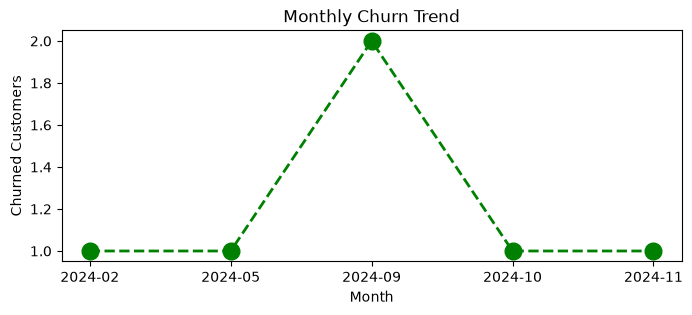

In [61]:
#4.1 Monthly Churn Trend (Time Series KPI )
df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churn_flag']==1].groupby('cancellation_month').size()
plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype('str'),churn_trend.values,color='green', marker='o', linestyle='dashed',linewidth=2, markersize=12)
plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()


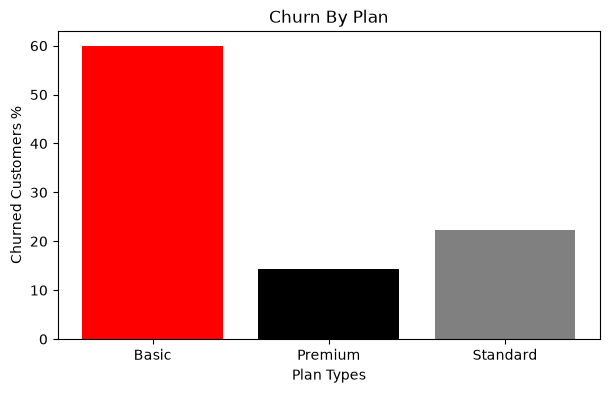

In [62]:
#4.2 CHURN BY PLAN TYPE.
churn_plan=df_visual.groupby('plan_type')['churn_flag'].mean()*100
plt.figure(figsize=(7,4))
colors = ['red','black','grey']
plt.bar(churn_plan.index,churn_plan.values,color=colors)
plt.title('Churn By Plan')
plt.xlabel('Plan Types')
plt.ylabel('Churned Customers %')
plt.show()

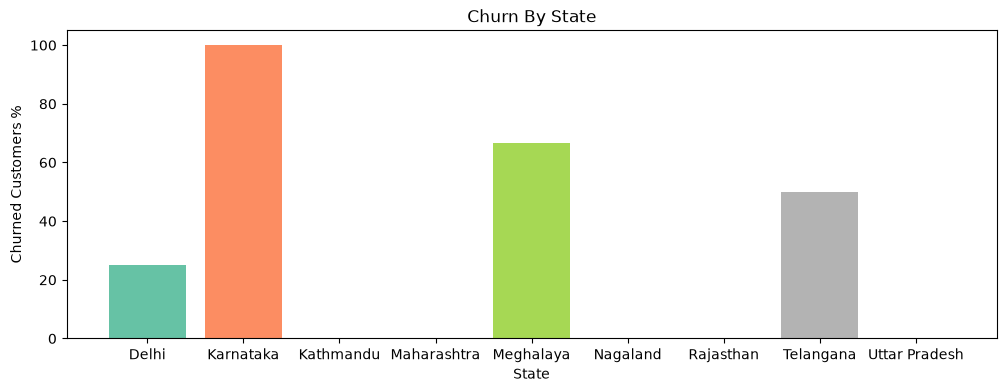

In [63]:
#4.3 Churn by state
churn_state = df_visual.groupby('state')['churn_flag'].mean()*100
plt.figure(figsize=(12,4))
colors = plt.cm.Set2(np.linspace(0,1,len(churn_state)))
plt.bar(churn_state.index,churn_state.values,color = colors)
plt.title('Churn By State')
plt.xlabel('State')
plt.ylabel('Churned Customers %')
plt.show()

In [64]:
#Visualization using Seaborn

In [65]:
df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,NaN
1,Premium,Annual,91,1,high,1.0
2,Basic,Monthly,34,0,low,NaN
3,Premium,Annual,8,0,low,NaN
4,Standard,Monthly,88,1,high,1.0


In [66]:
# Encoding based on priority
df_encoded = df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']]

order_mappings = {
    'plan_type':['Basic','Standard','Premium'],
    'contract_type':['Monthly','Annual'],
    'churn_risk':['low','medium','high']
}

for col,order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'),categories = order,ordered=True).codes
    

In [67]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,NaN
1,2,1,91,1,2,1.0
2,0,0,34,0,0,NaN
3,2,1,8,0,0,NaN
4,1,0,88,1,2,1.0


<Axes: >

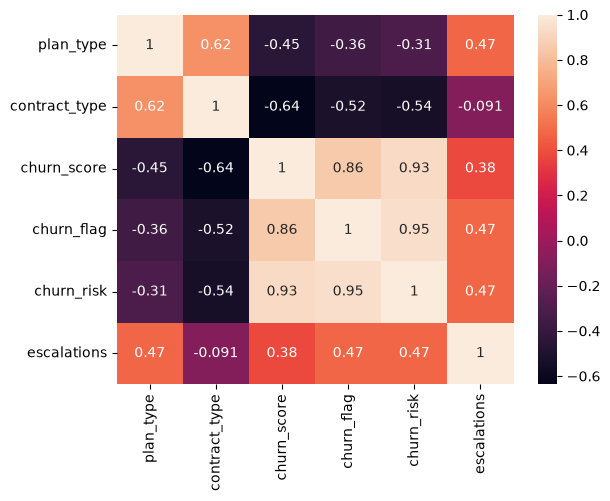

In [68]:
#Heatmap (Correlation Matrix)
sns.heatmap(df_encoded.corr(),annot = True)


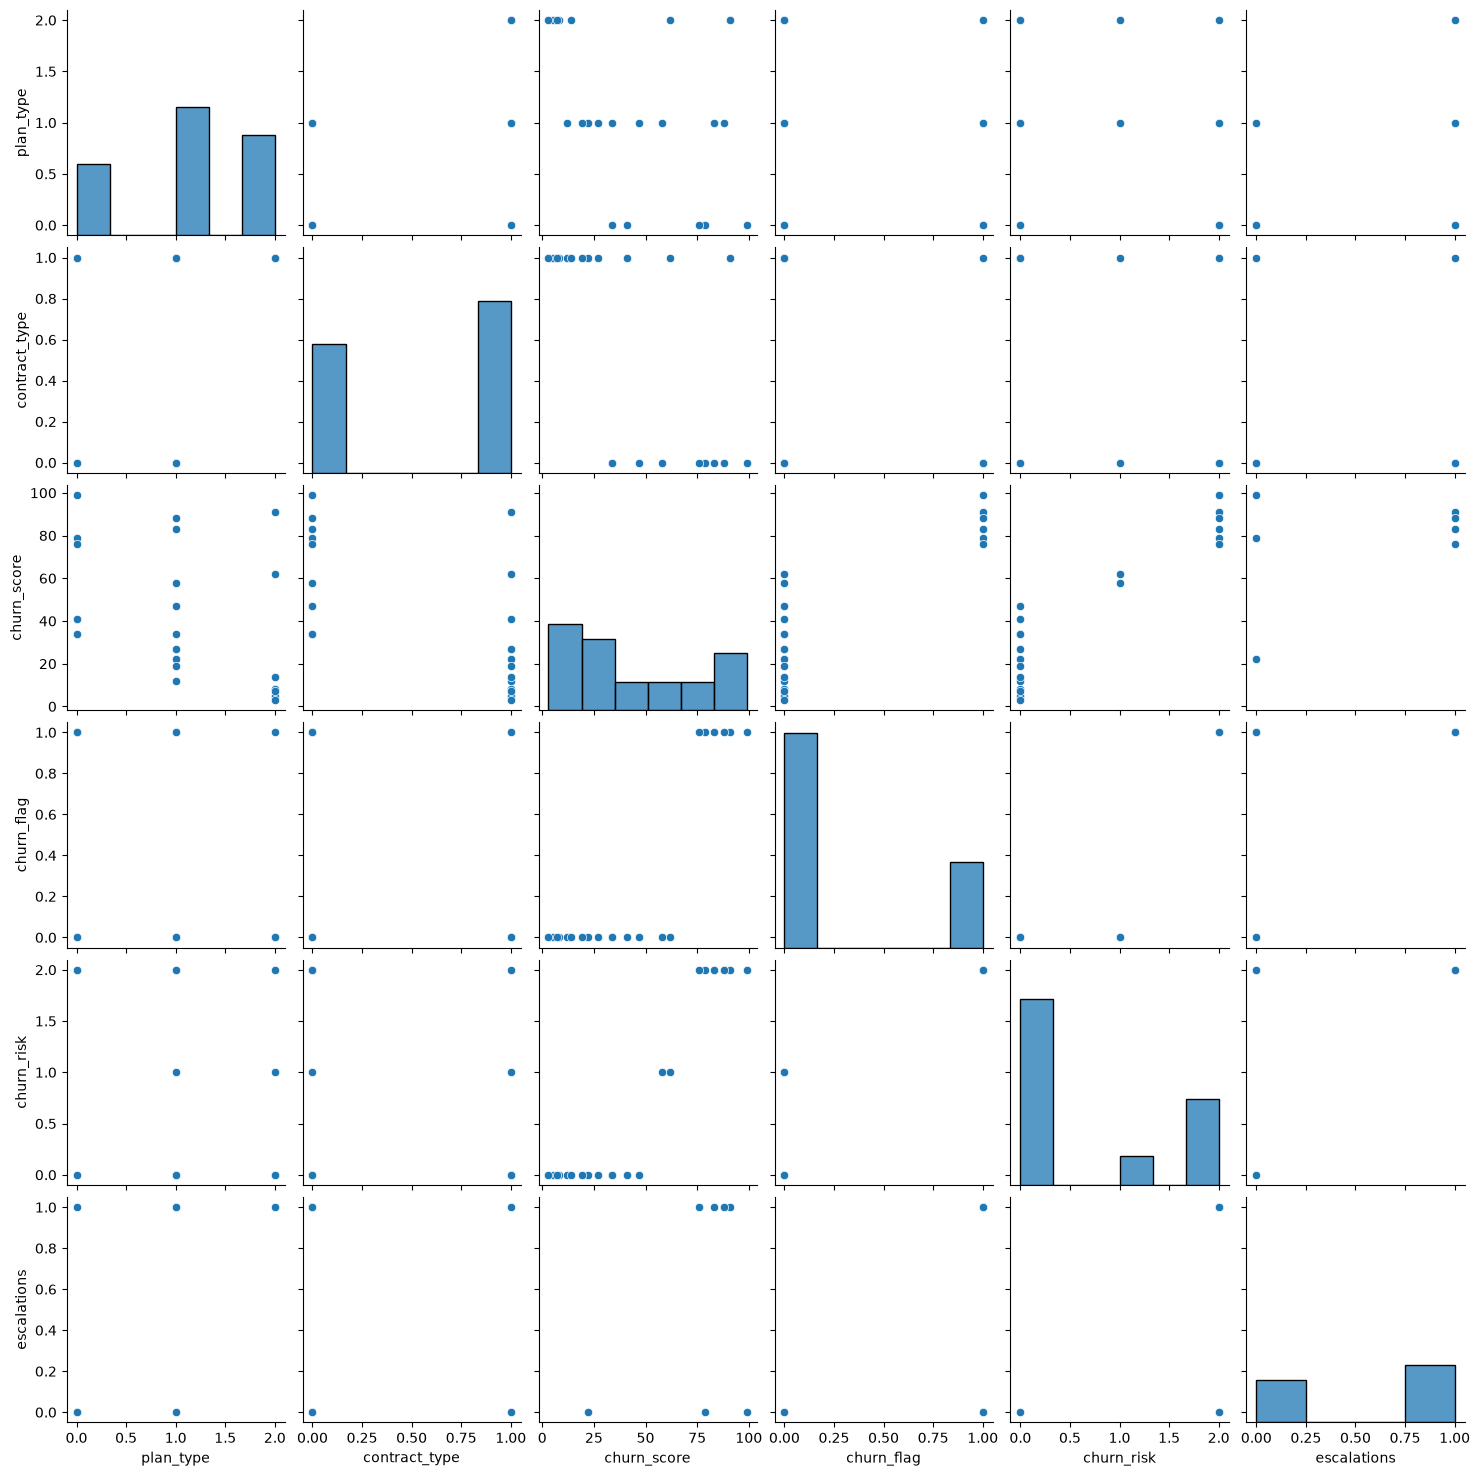

In [69]:
#pairplot- relationship in a dataset
sns.pairplot(df_encoded)

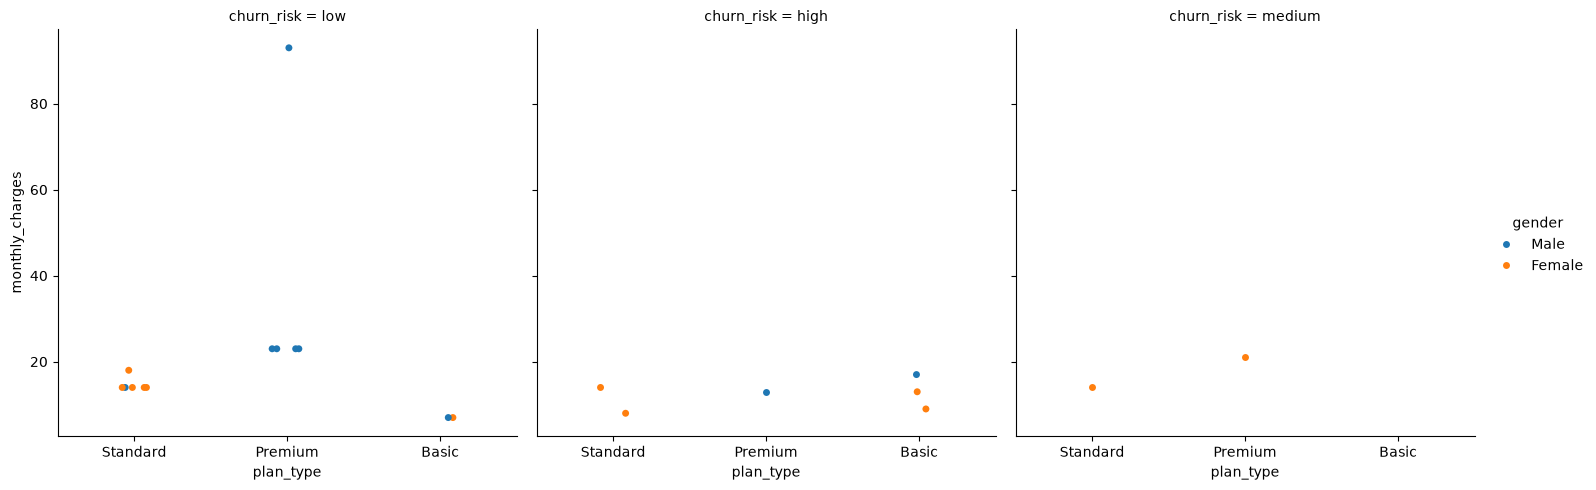

In [70]:
#catplot/facegrid plot- multi-dim comparison

sns.catplot(data=df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk')

In [71]:
#pivot table

pd.pivot_table(
    df_visual,
    values='churn_flag',
    index='plan_type',
    aggfunc='mean'   
).reset_index()

,plan_type,churn_flag
0,Basic,0.600000
1,Premium,0.142857
2,Standard,0.222222


In [72]:
pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges','customerid','churn_flag'],
    aggfunc={
    'monthly_charges':'sum',
    'customerid':'nunique',
    'churn_flag':'mean'
 }   
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91
